SESSÃO 06 — APRENDIZADO NÃO SUPERVISIONADO

Objetivo: investigar padrões multivariados nos dados reais de treinamento da V3 por meio de PCA, UMAP e K-means, utilizando atributos estatísticos dos sensores selecionados.

In [1]:

# SESSAO 06 - TAREFA 01
# Preparacao da matriz de atributos

import pandas as pd
from google.colab import files

print("Selecione 05_Estatisticas_Por_Arquivo_V3.csv")
enviados = files.upload()

arquivo = "05_Estatisticas_Por_Arquivo_V3.csv"
df = pd.read_csv(arquivo)

# Uma linha por arquivo; atributos nas colunas
matriz = df.pivot_table(
    index=["Arquivo", "Poco", "Categoria"],
    columns="Sensor",
    values=["Media", "Desvio_padrao"],
    aggfunc="first"
)

matriz.columns = [
    f"{metrica}_{sensor}"
    for metrica, sensor in matriz.columns
]

matriz = matriz.reset_index()

# Separar atributos numericos dos identificadores
colunas_atributos = [
    c for c in matriz.columns
    if c not in ["Arquivo", "Poco", "Categoria"]
]

X = matriz[colunas_atributos].copy()

print("\nARQUIVOS REPRESENTADOS:", len(matriz))
print("ATRIBUTOS:", len(colunas_atributos))

print("\nPRIMEIRAS LINHAS:")
display(matriz.head())

print("\nVALORES AUSENTES POR ATRIBUTO:")
display(X.isna().sum().to_frame("Ausentes"))

matriz.to_csv(
    "06_Matriz_Atributos_V3.csv",
    index=False
)


Selecione 05_Estatisticas_Por_Arquivo_V3.csv


Saving 05_Estatisticas_Por_Arquivo_V3.csv to 05_Estatisticas_Por_Arquivo_V3.csv

ARQUIVOS REPRESENTADOS: 470
ATRIBUTOS: 6

PRIMEIRAS LINHAS:


,Arquivo,Poco,Categoria,Desvio_padrao_P-ANULAR,Desvio_padrao_P-TPT,Desvio_padrao_T-TPT,Media_P-ANULAR,Media_P-TPT,Media_T-TPT
0,WELL-00002_20131104004101.parquet,WELL-00002,2,2.007492e+06,4.660480e+06,45.044661,1.598452e+07,1.512740e+07,80.079822
1,WELL-00002_20131208220000.parquet,WELL-00002,4,8.476736e+03,6.560517e+04,0.042004,1.625099e+07,1.660953e+07,118.158848
2,WELL-00002_20131209000000.parquet,WELL-00002,4,1.925355e+04,7.997141e+04,0.029964,1.627455e+07,1.676705e+07,118.114735
3,WELL-00002_20131209020000.parquet,WELL-00002,4,1.865484e+04,1.286133e+04,0.021544,1.629861e+07,1.683414e+07,118.097030
4,WELL-00002_20131209040000.parquet,WELL-00002,4,1.902290e+04,1.425618e+04,0.025114,1.630109e+07,1.683346e+07,118.091368



VALORES AUSENTES POR ATRIBUTO:


,Ausentes
Desvio_padrao_P-ANULAR,39
Desvio_padrao_P-TPT,6
Desvio_padrao_T-TPT,20
Media_P-ANULAR,39
Media_P-TPT,6
Media_T-TPT,20


VARIANCIA EXPLICADA:
PC1: 41.63%
PC2: 22.18%
Total: 63.81%

COEFICIENTES DOS ATRIBUTOS:


,PC1,PC2
Desvio_padrao_P-ANULAR,0.364,-0.024
Desvio_padrao_P-TPT,0.517,-0.375
Desvio_padrao_T-TPT,0.491,-0.436
Media_P-ANULAR,0.260,0.691
Media_P-TPT,0.367,0.296
Media_T-TPT,-0.398,-0.323


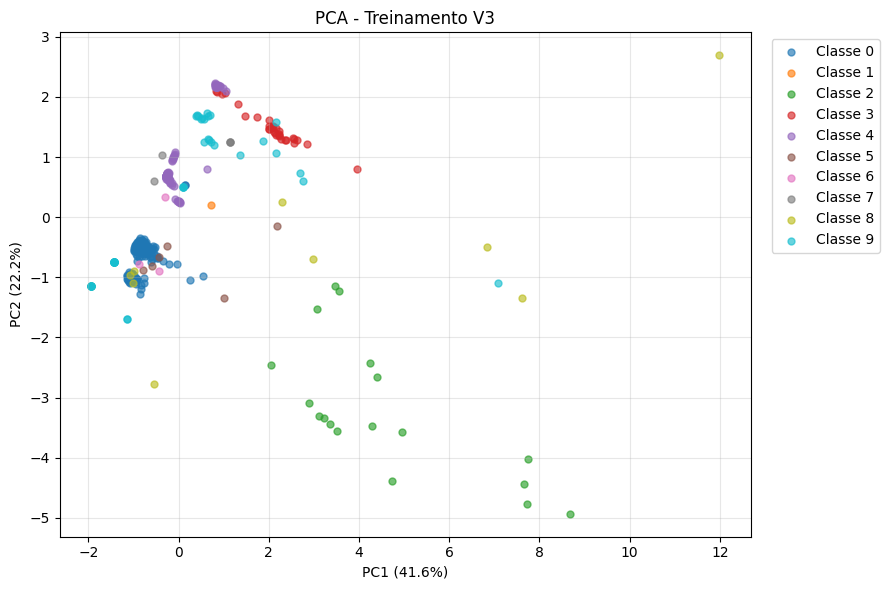


TAREFA 02 EXECUTADA


In [2]:

# SESSAO 06 - TAREFA 02
# Padronizacao e PCA

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# 1. Preencher valores ausentes pela mediana
imputador = SimpleImputer(strategy="median")
X_preenchido = imputador.fit_transform(X)

# 2. Padronizar os atributos
padronizador = StandardScaler()
X_padronizado = padronizador.fit_transform(X_preenchido)

# 3. Aplicar PCA com duas componentes
pca = PCA(n_components=2)
componentes = pca.fit_transform(X_padronizado)

# 4. Organizar os resultados
resultado_pca = matriz[
    ["Arquivo", "Poco", "Categoria"]
].copy()

resultado_pca["PC1"] = componentes[:, 0]
resultado_pca["PC2"] = componentes[:, 1]

# 5. Variancia explicada
variancia = pca.explained_variance_ratio_ * 100

print("VARIANCIA EXPLICADA:")
print(f"PC1: {variancia[0]:.2f}%")
print(f"PC2: {variancia[1]:.2f}%")
print(f"Total: {variancia.sum():.2f}%")

# 6. Contribuicao dos atributos nas componentes
contribuicoes = pd.DataFrame(
    pca.components_.T,
    index=colunas_atributos,
    columns=["PC1", "PC2"]
)

print("\nCOEFICIENTES DOS ATRIBUTOS:")
display(contribuicoes.round(3))

# 7. Grafico PCA por categoria
plt.figure(figsize=(9, 6))

for classe in sorted(resultado_pca["Categoria"].unique()):
    dados = resultado_pca[
        resultado_pca["Categoria"] == classe
    ]

    plt.scatter(
        dados["PC1"],
        dados["PC2"],
        label=f"Classe {classe}",
        alpha=0.65,
        s=25
    )

plt.xlabel(f"PC1 ({variancia[0]:.1f}%)")
plt.ylabel(f"PC2 ({variancia[1]:.1f}%)")
plt.title("PCA - Treinamento V3")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# 8. Salvar resultados
resultado_pca.to_csv(
    "06_Resultados_PCA_V3.csv",
    index=False
)

print("\nTAREFA 02 EXECUTADA")


/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


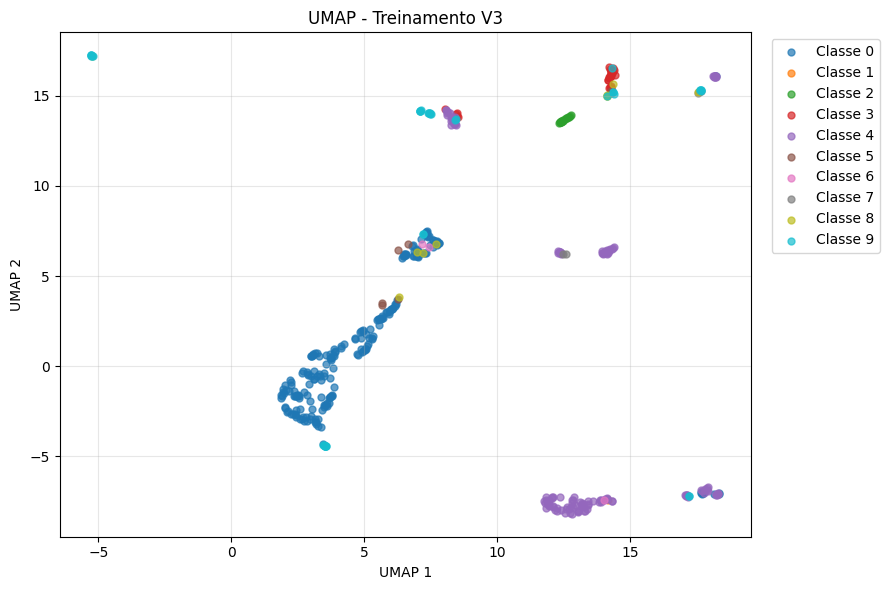

ARQUIVOS REPRESENTADOS: 470
CATEGORIAS REPRESENTADAS: 10

TAREFA 03 EXECUTADA


In [3]:

# SESSAO 06 - TAREFA 03
# Reducao de dimensionalidade com UMAP

import sys
import subprocess
import pandas as pd
import matplotlib.pyplot as plt

# Instalar a biblioteca apenas se necessario
try:
    import umap.umap_ as umap
except ImportError:
    subprocess.check_call([
        sys.executable, "-m", "pip",
        "install", "-q", "umap-learn"
    ])
    import umap.umap_ as umap

# 1. Aplicar UMAP aos atributos padronizados
modelo_umap = umap.UMAP(
    n_components=2,
    n_neighbors=15,
    min_dist=0.1,
    metric="euclidean",
    random_state=42
)

componentes_umap = modelo_umap.fit_transform(
    X_padronizado
)

# 2. Organizar os resultados
resultado_umap = matriz[
    ["Arquivo", "Poco", "Categoria"]
].copy()

resultado_umap["UMAP1"] = componentes_umap[:, 0]
resultado_umap["UMAP2"] = componentes_umap[:, 1]

# 3. Visualizar por categoria operacional
plt.figure(figsize=(9, 6))

for classe in sorted(resultado_umap["Categoria"].unique()):
    dados = resultado_umap[
        resultado_umap["Categoria"] == classe
    ]

    plt.scatter(
        dados["UMAP1"],
        dados["UMAP2"],
        label=f"Classe {classe}",
        alpha=0.7,
        s=25
    )

plt.title("UMAP - Treinamento V3")
plt.xlabel("UMAP 1")
plt.ylabel("UMAP 2")
plt.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# 4. Conferir e salvar
print("ARQUIVOS REPRESENTADOS:", len(resultado_umap))
print("CATEGORIAS REPRESENTADAS:",
      resultado_umap["Categoria"].nunique())

resultado_umap.to_csv(
    "06_Resultados_UMAP_V3.csv",
    index=False
)

print("\nTAREFA 03 EXECUTADA")


AVALIACAO DAS QUANTIDADES DE CLUSTERS:


,K,Silhueta
0,2,0.702
1,3,0.556
2,4,0.561
3,5,0.596
4,6,0.600
5,7,0.623
6,8,0.640
7,9,0.654
8,10,0.673



MELHOR K SEGUNDO A SILHUETA: 2

TAMANHO DOS CLUSTERS:


,Arquivos
Cluster,
0,447
1,23



CATEGORIAS POR CLUSTER:


Categoria,0,1,2,3,4,5,6,7,8,9
Cluster,,,,,,,,,,
0,211,1,0,30,143,6,3,5,7,41
1,0,0,18,1,0,0,0,0,3,1


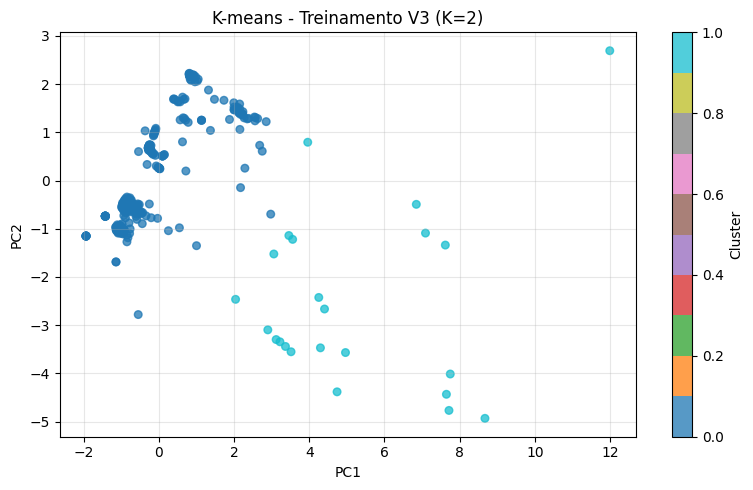


TAREFA 04 EXECUTADA


In [5]:

# SESSAO 06 - TAREFA 04
# Agrupamento K-means

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# 1. Comparar diferentes quantidades de clusters
resultados_k = []

for k in range(2, 11):

    modelo = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    grupos = modelo.fit_predict(X_padronizado)

    resultados_k.append({
        "K": k,
        "Silhueta": silhouette_score(
            X_padronizado, grupos
        )
    })

avaliacao_k = pd.DataFrame(resultados_k)

print("AVALIACAO DAS QUANTIDADES DE CLUSTERS:")
display(avaliacao_k.round(3))

# 2. Selecionar K com maior silhueta
melhor_k = int(
    avaliacao_k.loc[
        avaliacao_k["Silhueta"].idxmax(), "K"
    ]
)

print("\nMELHOR K SEGUNDO A SILHUETA:", melhor_k)

# 3. Aplicar K-means
kmeans = KMeans(
    n_clusters=melhor_k,
    random_state=42,
    n_init=10
)

clusters = kmeans.fit_predict(X_padronizado)

resultado_kmeans = matriz[
    ["Arquivo", "Poco", "Categoria"]
].copy()

resultado_kmeans["Cluster"] = clusters

# 4. Quantidade de arquivos por cluster
print("\nTAMANHO DOS CLUSTERS:")
display(
    resultado_kmeans["Cluster"]
    .value_counts()
    .sort_index()
    .to_frame("Arquivos")
)

# 5. Comparar clusters e categorias
print("\nCATEGORIAS POR CLUSTER:")
tabela_clusters = pd.crosstab(
    resultado_kmeans["Cluster"],
    resultado_kmeans["Categoria"]
)

display(tabela_clusters)

# 6. Visualizar clusters no espaco da PCA
plt.figure(figsize=(8, 5))

plt.scatter(
    resultado_pca["PC1"],
    resultado_pca["PC2"],
    c=clusters,
    cmap="tab10",
    s=30,
    alpha=0.75
)

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title(f"K-means - Treinamento V3 (K={melhor_k})")
plt.colorbar(label="Cluster")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# 7. Salvar resultados
avaliacao_k.to_csv(
    "06_Avaliacao_Kmeans_V3.csv",
    index=False
)

resultado_kmeans.to_csv(
    "06_Resultados_Kmeans_V3.csv",
    index=False
)

print("\nTAREFA 04 EXECUTADA")


In [6]:

# SESSAO 06 - TAREFA 05
# Relacao dos clusters com categorias e pocos

import pandas as pd
from sklearn.metrics import adjusted_rand_score

# 1. Quantidade de pocos distintos por cluster
resumo_pocos = resultado_kmeans.groupby("Cluster").agg(
    Arquivos=("Arquivo", "count"),
    Pocos_distintos=("Poco", "nunique")
)

print("COMPOSICAO DOS CLUSTERS:")
display(resumo_pocos)

# 2. Identificar os pocos e categorias do cluster 1
cluster1 = resultado_kmeans[
    resultado_kmeans["Cluster"] == 1
]

print("\nPOCOS E CATEGORIAS DO CLUSTER 1:")
display(
    pd.crosstab(
        cluster1["Poco"],
        cluster1["Categoria"]
    )
)

# 3. Concordancia entre clusters e categorias
ari = adjusted_rand_score(
    resultado_kmeans["Categoria"],
    resultado_kmeans["Cluster"]
)

print(f"\nINDICE ARI: {ari:.4f}")

# 4. Percentual de cada categoria por cluster
percentuais = pd.crosstab(
    resultado_kmeans["Categoria"],
    resultado_kmeans["Cluster"],
    normalize="index"
) * 100

print("\nDISTRIBUICAO PERCENTUAL POR CATEGORIA:")
display(percentuais.round(2))

# 5. Salvar resultados
resumo_pocos.to_csv(
    "06_Resumo_Pocos_Clusters_V3.csv"
)

percentuais.to_csv(
    "06_Categorias_Por_Cluster_V3.csv"
)

print("\nTAREFA 05 EXECUTADA")


COMPOSICAO DOS CLUSTERS:


,Arquivos,Pocos_distintos
Cluster,,
0,447,20
1,23,10



POCOS E CATEGORIAS DO CLUSTER 1:


Categoria,2,3,8,9
Poco,,,,
WELL-00002,1,0,0,0
WELL-00009,1,0,0,0
WELL-00011,13,0,0,0
WELL-00012,2,0,0,0
WELL-00013,1,0,0,0
WELL-00014,0,1,0,0
WELL-00020,0,0,0,1
WELL-00025,0,0,1,0
WELL-00029,0,0,1,0



INDICE ARI: 0.0847

DISTRIBUICAO PERCENTUAL POR CATEGORIA:


Cluster,0,1
Categoria,,
0,100.00,0.00
1,100.00,0.00
2,0.00,100.00
3,96.77,3.23
4,100.00,0.00
5,100.00,0.00
6,100.00,0.00
7,100.00,0.00
8,70.00,30.00



TAREFA 05 EXECUTADA


In [7]:
from google.colab import files

files.download("06_Matriz_Atributos_V3.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>